'''For figure 3A we will compute the mass that key processes or proteins contribute to in the E.coli and compare that to the mass of all the subgen genes (tiny). We use the E.coli cartoon and legend as a template for picking the key components to illustrate.'''

In [ ]:
#section 1: load the needed packages
import os
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

In [ ]:
# Local setup for the wcEcoli3 kernel (replaces the Colab paths).
# Run from notebooks/. Unspecified media -> minimal.
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NB_DIR    = Path.cwd()
DATA      = NB_DIR / 'data'                 # EcoCyc / UniProt / flow / RNA-seq / Schmidt
DATA_MIN  = DATA / '102126_minimal'         # simulation outputs, minimal media (default)
DATA_RICH = DATA / '102126_rich'            # simulation outputs, rich media
OUT_DIR   = NB_DIR / 'output' / 'fig3'      # all figures / tables / intermediates
assert DATA.is_dir(), f'run this notebook from notebooks/ (no data dir at {DATA})'
OUT_DIR.mkdir(parents=True, exist_ok=True)
PNG_DIR   = OUT_DIR / 'pngs'                 # every figure -> pngs/<name>.png
SVG_DIR   = OUT_DIR / 'svgs'                 #               + svgs/<name>.svg
PNG_DIR.mkdir(exist_ok=True)
SVG_DIR.mkdir(exist_ok=True)


def save_figure(fig, name, **kwargs):
    """Save one figure as pngs/<name>.png and svgs/<name>.svg (rcParams: 600 dpi, tight bbox)."""
    fig = fig if fig is not None else plt.gcf()
    fig.savefig(PNG_DIR / f'{name}.png', **kwargs)
    fig.savefig(SVG_DIR / f'{name}.svg', **kwargs)


In [ ]:
#section 2: Science-journal figure style (apply once; affects every plot)
import os
import matplotlib as mpl


# general categorical palette (tab10 order)
subgen_palette = [
    '#1f77b4',  # blue
    '#ff7f0e',  # orange
    '#2ca02c',  # green
    '#d62728',  # red
    '#9467bd',  # purple
    '#e6ab02',  # gold
    '#e377c2',  # pink
    '#7f7f7f',  # grey
    '#bcbd22',  # olive
    '#17becf',  # cyan
]
# matplotlib-only replacement for sns.set_style('white') + sns.set_palette()
mpl.rcParams.update({'axes.facecolor': 'white', 'figure.facecolor': 'white',
                     'axes.grid': False})
mpl.rcParams['axes.prop_cycle'] = mpl.cycler(color=subgen_palette)

mpl.rcParams.update({
    'font.family':        'sans-serif',
    'font.sans-serif':    ['Arial', 'Helvetica', 'DejaVu Sans'],
    'pdf.fonttype':        42,
    'ps.fonttype':         42,
    'font.size':           8,
    'axes.titlesize':      9,
    'axes.labelsize':      8,
    'xtick.labelsize':     7,
    'ytick.labelsize':     7,
    'legend.fontsize':     7,
    'figure.titlesize':    9,
    'text.color':          'black',
    'axes.labelcolor':     'black',
    'axes.edgecolor':      'black',
    'xtick.color':         'black',
    'ytick.color':         'black',
    'axes.linewidth':      0.6,
    'lines.linewidth':     1.0,
    'xtick.major.width':   0.6,
    'ytick.major.width':   0.6,
    'axes.spines.top':     False,
    'axes.spines.right':   False,
    'savefig.dpi':         600,
    'savefig.bbox':        'tight',
    'svg.fonttype':        'none',
})

# semantic colors reused across panels
COMPONENT_COLOR = subgen_palette[0]   # '#1f77b4' blue    — cell components
SUBGEN_COLOR    = subgen_palette[1]   # '#ff7f0e' orange  — sub-generational (highlight)

# figure sizes in Science column widths (cm -> inches)
CM = 1/2.54
FIG_1COL = (5.7*CM, 5.0*CM)
FIG_1_5  = (12.1*CM, 8.0*CM)
FIG_2COL = (18.4*CM, 10.0*CM)

SHOW_TITLES = False   # False for submission; True while developing

# --- one saver for every figure: PNG + SVG into OUT_DIR/pngs and OUT_DIR/svgs ---
FIG_DIR = str(OUT_DIR)
os.makedirs(FIG_DIR, exist_ok=True)
def save_fig(fig, name, png=True):
    save_figure(fig, name)   # -> pngs/<name>.png + svgs/<name>.svg


In [ ]:
#section 3: load and read the datasets: EcoCyc genes and complexes, subgen table, and the mass-info files.

# File paths
ecoli_genes_path    = f"{DATA}/All-genes-of-E.-coli-K-12-substr.-MG1655.txt"
monomer_mass_mw_path= f"{DATA_MIN}/subgen_subsample_mrna_protein_10k_monomer_mws.tsv"   # renamed MW file
subgen_mRNA_path    = f"{DATA_MIN}/subgen_expression_table.tsv"                          # renamed (was subgenerational_expression_table_def5.tsv)
monomer_counts_path = f"{DATA_MIN}/subgen_definitions_all.tsv"                           # counts now live here (no monomer_name column)
complexes_path      = f"{DATA}/All-proteins-(polypeptides-+-protein-complexes)-of-E.-coli-K-12-subst.txt"

# Read all files
# ecoli_genes_pd: EcoCyc export with Characterization, GO terms, Object ID (EG numbers), April 2026
ecoli_genes_pd     = pd.read_csv(ecoli_genes_path, sep='\t')
# monomer_mass_mw_pd: MW of each monomer (from the mass listener; static)
monomer_mass_mw_pd = pd.read_csv(monomer_mass_mw_path, sep='\t')
# subgen_mRNA_pd: sub-generational expression table (definition 5)
subgen_mRNA_pd     = pd.read_csv(subgen_mRNA_path, sep='\t')
# monomer_counts_pd: mean mRNA / protein counts per gene (monomer_name added from subgen_mRNA_pd in section 4)
monomer_counts_pd  = pd.read_csv(monomer_counts_path, sep='\t')
# complexes_pd: EcoCyc protein complexes (polypeptides + complexes)
complexes_pd       = pd.read_csv(complexes_path, sep='\t')

# fail early if a file swap dropped an expected column
_need = {
    'ecoli_genes_pd':     (ecoli_genes_pd,     ['Object ID', 'Gene Name', 'Product']),
    'monomer_mass_mw_pd': (monomer_mass_mw_pd, ['monomer_id', 'mw_g_per_mol']),
    'subgen_mRNA_pd':     (subgen_mRNA_pd,     ['gene_name', 'monomer_name', 'def5_CI_category', 'def5_CI_mean', 'p_any_synth_def4']),
    'monomer_counts_pd':  (monomer_counts_pd,  ['gene_name', 'mean_mRNA_count', 'mean_protein_count']),
    'complexes_pd':       (complexes_pd,       ['Proteins', 'Gene Name', 'Component-Of']),
}
for _name, (_df, _cols) in _need.items():
    _miss = [c for c in _cols if c not in _df.columns]
    assert not _miss, f"{_name} missing columns: {_miss}"

print(f"EcoCyc genes:   {len(ecoli_genes_pd)}")
print(f"Monomer MW:     {len(monomer_mass_mw_pd)}")
print(f"Subgen table:   {len(subgen_mRNA_pd)}")
print(f"Monomer counts: {len(monomer_counts_pd)}")
print(f"Complexes:      {len(complexes_pd)}")
print(f"\nSubgen categories:\n{subgen_mRNA_pd['def5_CI_category'].value_counts()}")

FileNotFoundError: [Errno 2] No such file or directory: '/content/subgen_data/subgen_subsample_mrna_protein_10k_monomer_mws.tsv'

In [ ]:
#section 4: prepare files to merge, have to rename some columns, drop duplicate columns

#Prepare monomer_mass_mw_pd, change column name to monomer_name so I can merge it to monomer_counts
monomer_mass = monomer_mass_mw_pd[['monomer_id','mw_g_per_mol' ]].copy()
monomer_mass.columns = ['monomer_name', 'mw_g_per_mol']

# Counts now come from subgen_definitions_all.tsv, which has NO monomer_name column.
# Bring monomer_name in from the expression table (1 monomer per gene, verified: all 4311 match).
monomer_counts = monomer_counts_pd[['gene_name','mean_mRNA_count','mean_protein_count']].copy()
monomer_counts = monomer_counts.merge(
    subgen_mRNA_pd[['gene_name','monomer_name']], on='gene_name', how='left')
monomer_counts = monomer_counts[['gene_name','monomer_name','mean_mRNA_count','mean_protein_count']]
assert monomer_counts['monomer_name'].notna().all(), \
    "monomer_name missing after merge — gene_name mismatch between counts and expression table"

#Make a copy of subgen_mRNA_pd and only pooled some key columns, revise later if needed
subgen_mRNA = subgen_mRNA_pd[['gene_name', 'def5_CI_category',
                              'def5_CI_mean', 'p_any_synth_def4']].copy()

#Merge monomer_mass with monomer_counts by monomer_name
monomer_counts_mass= monomer_counts.merge(monomer_mass, how='left', on='monomer_name')

#Now merge in subgen_mRNA
monomer_data= monomer_counts_mass.merge(subgen_mRNA, how='left', on='gene_name')

#add column to calculate mass in Fg
monomer_data['monomer_mass_fg'] = monomer_data['mean_protein_count'] * monomer_data['mw_g_per_mol'] * 1.66054e-9
assert monomer_data['monomer_mass_fg'].notna().all(), \
    "null masses — a monomer_name failed to match the MW file"

#Check columns
monomer_data.head()

,gene_name,monomer_name,mean_mRNA_count,mean_protein_count,mw_g_per_mol,def5_CI_category,def5_CI_mean,p_any_synth_def4,monomer_mass_fg
0,EG10001,ALARACEBIOSYN-MONOMER[c],0.156900,65.810481,39150.873,not_subgen,6.427470,0.997685,0.004278
1,EG10002,MODB-MONOMER[i],0.427005,85.350541,24945.829,not_subgen,2.726850,0.932870,0.003536
2,EG10003,EG10003-MONOMER[i],0.145407,206.099992,29313.012,not_subgen,3.349540,0.966821,0.010032
3,EG10004,EG10004-MONOMER[c],0.355727,228.315655,43438.093,not_subgen,6.963730,0.996914,0.016469
4,EG10006,DCUB-MONOMER[i],0.004014,3.951411,47936.191,subgen,0.027778,0.027006,0.000315


In [ ]:
#section 5: merge monomer data with the ecocyc table, have to change gene_name to Object ID

#Prepare monomer_data, change column name
monomer_data_new = monomer_data.rename(columns={'gene_name': 'Object ID'})

#Make copy of EcocyC table

all_ecoli_genes_pd = ecoli_genes_pd.copy()

monomer_master= monomer_data_new.merge(all_ecoli_genes_pd, how='left', on='Object ID')

# Skip possibly_subgen genes everywhere: remove them from the universe upstream
# so all downstream figures (mass bars, totals, percentages) ignore them.
# complexes_master is built from monomer_master below, so it inherits this too.
before = len(monomer_master)
monomer_master = monomer_master[monomer_master['def5_CI_category'] != 'possibly_subgen'].copy()
print(f"Dropped possibly_subgen: {before} -> {len(monomer_master)} rows "
      f"({before - len(monomer_master)} removed)")

#Check columns
monomer_master.head()

#Check columns
monomer_master.head()

Dropped possibly_subgen: 4311 -> 4249 rows (62 removed)


,Object ID,monomer_name,mean_mRNA_count,mean_protein_count,mw_g_per_mol,def5_CI_category,def5_CI_mean,p_any_synth_def4,monomer_mass_fg,Gene Name,Accession-1,Left-End-Position,Right-End-Position,Product,Characterization,GO terms (biological process),Accession-2,Common-Name
0,EG10001,ALARACEBIOSYN-MONOMER[c],0.156900,65.810481,39150.873,not_subgen,6.427470,0.997685,0.004278,alr,b4053,4265782.0,4266861.0,alanine racemase 1,WELL-CHARACTERIZED,cell wall organization // alanine metabolic pr...,ECK4045,alr
1,EG10002,MODB-MONOMER[i],0.427005,85.350541,24945.829,not_subgen,2.726850,0.932870,0.003536,modB,b0764,795862.0,796551.0,molybdate ABC transporter membrane subunit,WELL-CHARACTERIZED,tungstate ion transport // transmembrane trans...,ECK0753,modB
2,EG10003,EG10003-MONOMER[i],0.145407,206.099992,29313.012,not_subgen,3.349540,0.966821,0.010032,cysZ,b2413,2531463.0,2532224.0,sulfate:H+ symporter,WELL-CHARACTERIZED,amino acid biosynthetic process // proton tran...,ECK2408,cysZ
3,EG10004,EG10004-MONOMER[c],0.355727,228.315655,43438.093,not_subgen,6.963730,0.996914,0.016469,dfp,b3639,3812731.0,3813951.0,fused 4'-phosphopantothenoylcysteine decarboxy...,WELL-CHARACTERIZED,pantothenate catabolic process // coenzyme A b...,ECK3629,dfp
4,EG10006,DCUB-MONOMER[i],0.004014,3.951411,47936.191,subgen,0.027778,0.027006,0.000315,dcuB,b4123,4347404.0,4348744.0,anaerobic C4-dicarboxylate transporter DcuB,WELL-CHARACTERIZED,transmembrane transport // succinate transmemb...,ECK4116,dcuB


In [ ]:
#Section 6: merged with monomer master and explode

import html

cx = complexes_pd.copy()

cx["Gene Name"] = cx["Gene Name"].fillna("").apply(
    lambda s: [html.unescape(g.strip()) for g in s.split("//") if g.strip()])

cx = cx.explode("Gene Name").reset_index(drop=True)

print(cx.shape)
cx.head(10)

(6663, 3)


,Proteins,Gene Name,Component-Of
0,L(+)-tartrate dehydratase subunit &beta;,ttdB,L(+)-tartrate dehydratase subunit alpha // L(+...
1,tetratricopeptide-like domain-containing prote...,yibG,NaN
2,DcuS-DcuB sensor complex,dcuS,NaN
3,DcuS-DcuB sensor complex,dcuB,NaN
4,ATP-dependent Clp protease ATP-binding subunit...,clpX,ClpX ATP-dependent protease specificity compon...
5,protein YecU,yecU,NaN
6,RNase D,rnd,NaN
7,carbonic anhydrase 2,can,NaN
8,iron-sulfur cluster carrier protein NfuA,nfuA,[Fe-S] cluster carrier protein NfuA
9,ribonucleoside-diphosphate reductase 1,nrdB,NaN


In [ ]:
#section 7: made complexes_master by merging cx (the row split complex data frame) with monome_master on Gene Name
complexes_master = monomer_master.copy().merge(cx, on="Gene Name", how="left")

print(complexes_master.shape)
complexes_master.head()

(6514, 20)


,Object ID,monomer_name,mean_mRNA_count,mean_protein_count,mw_g_per_mol,def5_CI_category,def5_CI_mean,p_any_synth_def4,monomer_mass_fg,Gene Name,Accession-1,Left-End-Position,Right-End-Position,Product,Characterization,GO terms (biological process),Accession-2,Common-Name,Proteins,Component-Of
0,EG10001,ALARACEBIOSYN-MONOMER[c],0.156900,65.810481,39150.873,not_subgen,6.42747,0.997685,0.004278,alr,b4053,4265782.0,4266861.0,alanine racemase 1,WELL-CHARACTERIZED,cell wall organization // alanine metabolic pr...,ECK4045,alr,alanine racemase 1,alanine racemase 1
1,EG10001,ALARACEBIOSYN-MONOMER[c],0.156900,65.810481,39150.873,not_subgen,6.42747,0.997685,0.004278,alr,b4053,4265782.0,4266861.0,alanine racemase 1,WELL-CHARACTERIZED,cell wall organization // alanine metabolic pr...,ECK4045,alr,alanine racemase 1,NaN
2,EG10002,MODB-MONOMER[i],0.427005,85.350541,24945.829,not_subgen,2.72685,0.932870,0.003536,modB,b0764,795862.0,796551.0,molybdate ABC transporter membrane subunit,WELL-CHARACTERIZED,tungstate ion transport // transmembrane trans...,ECK0753,modB,molybdate ABC transporter membrane subunit,molybdate ABC transporter
3,EG10002,MODB-MONOMER[i],0.427005,85.350541,24945.829,not_subgen,2.72685,0.932870,0.003536,modB,b0764,795862.0,796551.0,molybdate ABC transporter membrane subunit,WELL-CHARACTERIZED,tungstate ion transport // transmembrane trans...,ECK0753,modB,molybdate ABC transporter,NaN
4,EG10003,EG10003-MONOMER[i],0.145407,206.099992,29313.012,not_subgen,3.34954,0.966821,0.010032,cysZ,b2413,2531463.0,2532224.0,sulfate:H+ symporter,WELL-CHARACTERIZED,amino acid biosynthetic process // proton tran...,ECK2408,cysZ,sulfate:H+ symporter,NaN


In [ ]:
#Section 8: Some genes participate in more than one complex, which is fine, so just keep track of any overlapping genes in complexes we choose
#Final mass then will be calculated from monomer_master
print("monomer_master rows:", len(monomer_master))
print("complexes_master rows:", len(complexes_master))
dupes = complexes_master['Gene Name'].value_counts()
print("genes appearing in >1 complex:", (dupes > 1).sum())

monomer_master rows: 4249
complexes_master rows: 6514
genes appearing in >1 complex: 1675


In [ ]:
# Section 9: de-duplicated gene -> (mass, category), one row per gene
gene_tbl = (complexes_master[['Gene Name', 'monomer_mass_fg', 'def5_CI_category']]
            .dropna(subset=['Gene Name'])
            .drop_duplicates('Gene Name'))

subgen = gene_tbl[gene_tbl['def5_CI_category'] == 'subgen']
total  = gene_tbl['monomer_mass_fg'].sum()

print(f"subgen genes: {subgen['Gene Name'].nunique()}")
print(f"subgen mass:  {subgen['monomer_mass_fg'].sum():.3f} fg "
      f"({100*subgen['monomer_mass_fg'].sum()/total:.2f}% of total)")

subgen genes: 1848
subgen mass:  3.020 fg (1.41% of total)


In [ ]:
print("monomer_data has monomer_mass_fg:    ", 'monomer_mass_fg' in monomer_data.columns)
print("monomer_master has monomer_mass_fg:  ", 'monomer_mass_fg' in monomer_master.columns)
print("complexes_master has monomer_mass_fg:", 'monomer_mass_fg' in complexes_master.columns)

monomer_data has monomer_mass_fg:     True
monomer_master has monomer_mass_fg:   True
complexes_master has monomer_mass_fg: True


In [ ]:
#Section 10:
sub = monomer_master.drop_duplicates('Gene Name')
subgen_mass = sub.loc[sub['def5_CI_category'] == 'subgen', 'monomer_mass_fg'].sum()
print(f"{(sub['def5_CI_category']=='subgen').sum()} subgen genes, {subgen_mass:.3f} fg")

1848 subgen genes, 3.020 fg


In [ ]:
#Section 11:
df = complexes_master
gene_mass = (df[['Gene Name','monomer_mass_fg']].dropna(subset=['Gene Name'])
             .drop_duplicates('Gene Name').set_index('Gene Name')['monomer_mass_fg'])

# all "polymerase" labels, then drop non-nucleic-acid (sugar/O-antigen) polymerases
mask = pd.Series(False, index=df.index)
for col in ['Component-Of', 'Proteins']:
    mask |= df[col].fillna('').str.contains('polymerase', case=False)
drop = df['Gene Name'].isin(['wzzB','wzzE','wzyE','wbbH','wcaD','fepE'])

poly_genes = df.loc[mask & ~drop, 'Gene Name'].dropna().unique()
print(len(poly_genes), f"genes, {gene_mass.reindex(poly_genes).sum():.3f} fg")

28 genes, 2.759 fg


In [ ]:
#Section 12:
df = complexes_master
gene_mass = (df[['Gene Name', 'monomer_mass_fg']].dropna(subset=['Gene Name'])
             .drop_duplicates('Gene Name')
             .set_index('Gene Name')['monomer_mass_fg'])

# 12 canonical nucleoid-associated proteins (Azam & Ishihama 1999, J. Bacteriol. 181:6361-6370)
# mapping protein -> gene(s); IciA = argP; HU and IHF each have two subunits
nap_proteins = {
    'CbpA':      ['cbpA'],
    'CbpB/Rob':  ['rob'],
    'DnaA':      ['dnaA'],
    'Dps':       ['dps'],
    'Fis':       ['fis'],
    'Hfq':       ['hfq'],
    'H-NS':      ['hns'],
    'HU':        ['hupA', 'hupB'],
    'IciA':      ['argP'],
    'IHF':       ['ihfA', 'ihfB'],
    'Lrp':       ['lrp'],
    'StpA':      ['stpA'],
}

nap_genes = [g for genes in nap_proteins.values() for g in genes]

# verify every gene resolves to a mass — flag any that don't
missing = [g for g in nap_genes if g not in gene_mass.index]
assert not missing, f"NAP genes not found in gene_mass: {missing}"

nap_mass = gene_mass.reindex(nap_genes)
print(f"{len(nap_proteins)} proteins, {len(nap_genes)} genes, {nap_mass.sum():.3f} fg\n")
print(nap_mass.sort_values(ascending=False).to_string())

12 proteins, 14 genes, 3.132 fg

Gene Name
hns     1.135886
hupA    0.609160
dps     0.328952
hupB    0.257906
stpA    0.200211
fis     0.134108
lrp     0.112186
ihfB    0.106916
ihfA    0.082785
hfq     0.076936
rob     0.034730
argP    0.027352
cbpA    0.017037
dnaA    0.007408


In [ ]:
#Section 13:
# cat = per-gene category lookup (also defined in section 15; defined here too so
# this cell runs top-to-bottom without depending on a later cell)
cat = monomer_master.drop_duplicates('Gene Name').set_index('Gene Name')['def5_CI_category']

nap_sub = [g for g in nap_genes if cat.get(g) == 'subgen']
print("subgen NAP gene(s):", nap_sub)
print(monomer_master[monomer_master['Gene Name'].isin(nap_sub)]
      [['Gene Name','monomer_name','def5_CI_category','def5_CI_mean','mean_protein_count','monomer_mass_fg']]
      .drop_duplicates().to_string(index=False))

subgen NAP gene(s): []
Empty DataFrame
Columns: [Gene Name, monomer_name, def5_CI_category, def5_CI_mean, mean_protein_count, monomer_mass_fg]
Index: []


In [ ]:
# Section 14:
dup = monomer_master.groupby('Gene Name')['monomer_mass_fg'].nunique()
print("genes with >1 distinct mass value:", (dup > 1).sum())
print("unique genes:", monomer_master['Gene Name'].nunique(),
      "| total protein mass:", f"{monomer_master.drop_duplicates('Gene Name')['monomer_mass_fg'].sum():.1f} fg")

genes with >1 distinct mass value: 0
unique genes: 4249 | total protein mass: 213.8 fg


central carbon metabolism: 52 genes, 18.78 fg


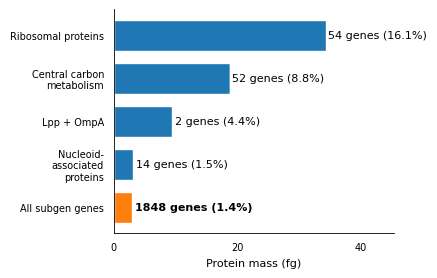

In [ ]:
# Section 15:  Fig 3A: subgen mass vs key components (with central carbon metabolism)
import textwrap
import matplotlib.pyplot as plt

# ── load the superpathway gene list ──
cem = pd.read_csv(f"{DATA}/central_energy_metabolism_pathway_Ecoli_K12_MG1655.txt", sep="\t")
metab_genes = [g.strip() for g in cem.iloc[0]['Genes of pathway'].split('//') if g.strip()]

df = complexes_master
gene_mass = (df[['Gene Name', 'monomer_mass_fg']].dropna(subset=['Gene Name'])
             .drop_duplicates('Gene Name').set_index('Gene Name')['monomer_mass_fg'])
cat = monomer_master.drop_duplicates('Gene Name').set_index('Gene Name')['def5_CI_category']

present = [g for g in metab_genes if g in gene_mass.index]
print(f"central carbon metabolism: {len(present)} genes, {gene_mass.reindex(present).sum():.2f} fg")

def genes_for(kind, keys):
    if kind == 'gene':
        return df.loc[df['Gene Name'].isin(keys), 'Gene Name'].dropna().unique()
    if kind == 'component':
        return df.loc[df['Component-Of'].isin(keys), 'Gene Name'].dropna().unique()
    return keys

groups = {
    'Ribosomal proteins':         ('component', ['ribosome']),
    'Central carbon metabolism':  ('explicit',  present),
    'Lpp + OmpA':                 ('gene',      ['lpp', 'ompA']),
    'Nucleoid-associated proteins': ('explicit', nap_genes),
}

total_mass = monomer_master.drop_duplicates('Gene Name')['monomer_mass_fg'].sum()

rows = {}
for name, (kind, keys) in groups.items():
    g = genes_for(kind, keys)
    sub_g = [x for x in g if cat.get(x) == 'subgen']
    rows[name] = {'n_genes': len(g),
                  'mass_fg': gene_mass.reindex(g).sum(),
                  'sub_mass': gene_mass.reindex(sub_g).sum()}

sub = monomer_master.drop_duplicates('Gene Name')
sub_total = sub.loc[sub['def5_CI_category'] == 'subgen', 'monomer_mass_fg'].sum()
rows['All subgen genes'] = {'n_genes': int((sub['def5_CI_category'] == 'subgen').sum()),
                            'mass_fg': sub_total, 'sub_mass': sub_total}

comp = pd.DataFrame(rows).T
comp[['mass_fg', 'sub_mass']] = comp[['mass_fg', 'sub_mass']].astype(float)
comp['n_genes'] = comp['n_genes'].astype(int)
comp = comp.sort_values('mass_fg')
comp['pct'] = 100 * comp['mass_fg'] / total_mass

# ── colors from the house palette (section 2) ──
COMPONENT = COMPONENT_COLOR   # blue    — cell components
SUBGEN    = SUBGEN_COLOR      # orange  — sub-generational
wrapped = {i: '\n'.join(textwrap.wrap(i, 18)) for i in comp.index}

fig, ax = plt.subplots(figsize=(7, 2.9))
for i, (name, r) in enumerate(comp.iterrows()):
    if name == 'All subgen genes':
        ax.barh(i, r['mass_fg'], color=SUBGEN, height=0.72)
    else:
        non_sub = r['mass_fg'] - r['sub_mass']
        ax.barh(i, non_sub, color=COMPONENT, height=0.72)
        if r['sub_mass'] > 0:                       # subgen slice within a component
            ax.barh(i, r['sub_mass'], left=non_sub, color=SUBGEN, height=0.72)

ax.set_yticks(range(len(comp)))
ax.set_yticklabels([wrapped[i] for i in comp.index])
ax.set_xlabel('Protein mass (fg)')
ax.set_xlim(0, comp['mass_fg'].max() * 1.32)
ax.set_xticks([0, 20, 40])


for i, (name, r) in enumerate(comp.iterrows()):
    subb = name == 'All subgen genes'
    gene_word = 'gene' if r['n_genes'] == 1 else 'genes'
    ax.text(r['mass_fg'] + comp['mass_fg'].max() * 0.012, i,
            f"{int(r['n_genes'])} {gene_word} ({r['pct']:.1f}%)",
            va='center',
            color='black', weight='bold' if subb else 'normal')

for s in ['top', 'right']:
    ax.spines[s].set_visible(False)

fig.subplots_adjust(left=0.50)
save_fig(fig, 'fig3A_components_vs_subgen_metabolism')   # -> pngs/ + svgs/
plt.show()

In [ ]:
missing_metab = [g for g in metab_genes if g not in gene_mass.index]
print("missing from gene_mass:", missing_metab)

# category of each missing gene in the UNFILTERED table
_pre = monomer_data_new.merge(ecoli_genes_pd.copy(), how='left', on='Object ID').drop_duplicates('Gene Name')
_cat_pre = _pre.set_index('Gene Name')['def5_CI_category']
for g in missing_metab:
    print(f"  {g:8s} -> {_cat_pre.get(g, 'NOT IN PIPELINE')}")

missing from gene_mass: ['fumC']
  fumC     -> possibly_subgen


In [ ]:
print('gapA' in metab_genes)          # is it in the pathway list?
print('gapA' in present)              # did it survive the mass-lookup filter?
print('gapA' in gene_mass.index)      # does it have a mass value?

True
True
True


In [ ]:
print("possibly_subgen still present?",
      (monomer_master['def5_CI_category'] == 'possibly_subgen').any())  # should be False

possibly_subgen still present? False


In [ ]:
# did the upstream filter actually drop rows?
print("possibly_subgen in monomer_master:",
      (monomer_master['def5_CI_category'] == 'possibly_subgen').sum())   # expect 0

# how much did total_mass change? compare to the pre-filter total
print("current total_mass:",
      monomer_master.drop_duplicates('Gene Name')['monomer_mass_fg'].sum())

possibly_subgen in monomer_master: 0
current total_mass: 213.7919615285764


In [ ]:
# Mass carried by the 62 possibly_subgen genes.
# Rebuild the pre-filter table just for this check (monomer_master is already filtered).
_check = monomer_data_new.merge(ecoli_genes_pd.copy(), how='left', on='Object ID')
_check = _check.drop_duplicates('Gene Name')

poss = _check[_check['def5_CI_category'] == 'possibly_subgen']

# current total (possibly_subgen already removed from monomer_master)
total_now = monomer_master.drop_duplicates('Gene Name')['monomer_mass_fg'].sum()

poss_mass = poss['monomer_mass_fg'].sum()

print(f"possibly_subgen genes: {poss['Gene Name'].nunique()}")
print(f"their total mass:      {poss_mass:.4f} fg")
print(f"current total mass:    {total_now:.2f} fg")
print(f"they would have been:  {100*poss_mass/(total_now+poss_mass):.3f}% of the (pre-filter) total")
print(f"mean mass per gene:    {poss_mass/max(poss['Gene Name'].nunique(),1):.5f} fg")

possibly_subgen genes: 62
their total mass:      0.4050 fg
current total mass:    213.79 fg
they would have been:  0.189% of the (pre-filter) total
mean mass per gene:    0.00653 fg


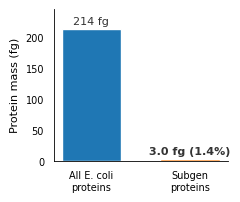

In [ ]:
#Plot subgen mass versus all mass (protein mass)
import matplotlib.pyplot as plt

gm = monomer_master.drop_duplicates('Gene Name')
total_mass  = gm['monomer_mass_fg'].sum()
n_total     = gm['Gene Name'].nunique()

sub_mask    = gm['def5_CI_category'] == 'subgen'
subgen_mass = gm.loc[sub_mask, 'monomer_mass_fg'].sum()
n_subgen    = int(sub_mask.sum())
pct         = 100 * subgen_mass / total_mass

COMPONENT = COMPONENT_COLOR   # blue    — cell components
SUBGEN    = SUBGEN_COLOR      # orange  — sub-generational

labels = ['All E. coli\nproteins', 'Subgen\nproteins']
values = [total_mass, subgen_mass]
colors = [COMPONENT, SUBGEN]

fig, ax = plt.subplots(figsize=FIG_1COL)
ax.bar(labels, values, color=colors, width=0.6)
ax.set_ylabel('Protein mass (fg)')
ax.set_ylim(0, total_mass * 1.15)

ax.text(0, total_mass + total_mass * 0.02, f"{total_mass:.0f} fg",
        ha='center', va='bottom', color='#333333')
ax.text(1, subgen_mass + total_mass * 0.02, f"{subgen_mass:.1f} fg ({pct:.1f}%)",
        ha='center', va='bottom', color='#333333', weight='bold')

save_fig(fig, 'fig3A_total_vs_subgen_mass')              # distinct name (not the metabolism bar)
plt.show()

In [ ]:
gm = monomer_master.drop_duplicates('Gene Name')
print("n genes (filtered):", gm['Gene Name'].nunique())
print("total_mass:        ", gm['monomer_mass_fg'].sum())
print("subgen mass:       ", gm.loc[gm['def5_CI_category']=='subgen','monomer_mass_fg'].sum())
print("possibly_subgen still present:", (gm['def5_CI_category']=='possibly_subgen').any())

# per-category mass breakdown, to see where any change is coming from
print(gm.groupby('def5_CI_category')['monomer_mass_fg'].agg(['count','sum']))

n genes (filtered): 4249
total_mass:         213.7919615285764
subgen mass:        3.0202508208295566
possibly_subgen still present: False
                  count           sum
def5_CI_category                     
never_expressed     137  1.345430e-07
not_subgen         2264  2.107717e+02
subgen             1848  3.020251e+00


In [ ]:
#Figure 3H, Volcano plot to compare gene expression between minimal and rich media:
# =====================================================================
# CELL 1 — Load and align the strict-seed summaries
# ---------------------------------------------------------------------
# Steps:
#   1. Set the paths to the minimal and rich category files.
#   2. Read both TSVs (one row per gene: mean, std, n_seeds, category).
#   3. Keep only the columns the volcano needs.
#   4. Merge minimal and rich on gene_id + cistron_id so each gene has
#      one row with both media side by side (_min / _rich suffixes).
#   4b. Drop possibly_subgen genes (borderline; most sit right on the
#      mean=1 cutoff and flicker between classes). A gene that is
#      possibly_subgen in EITHER medium is removed, matching the
#      mass-analysis filter (section 5). Every later cell reads `v`, so
#      this is the only place the filter is needed.
#   5. Print gene count, seed counts, and the first rows as a sanity check.
# Output: table `v`, used by every later cell.
# =====================================================================
import numpy as np
import pandas as pd

# 1. paths
min_path  = f"{DATA_MIN}/subgen_seed_ci_pergene_successful.tsv"
rich_path = f"{DATA_RICH}/subgen_seed_ci_pergene_successful.tsv"

# 2. load
mn = pd.read_csv(min_path,  sep='\t')
rc = pd.read_csv(rich_path, sep='\t')

# 3-4. keep needed columns, merge into one row per gene
cols = ['gene_id', 'cistron_id', 'n_seeds', 'mean', 'std', 'category']
v = mn[cols].merge(rc[cols], on=['gene_id', 'cistron_id'], suffixes=('_min', '_rich'))

# 4b. drop possibly_subgen (either medium)
_before = len(v)
_poss = (v['category_min'] == 'possibly_subgen') | (v['category_rich'] == 'possibly_subgen')
v = v[~_poss].copy()
print(f"dropped possibly_subgen (either medium): {_before} -> {len(v)} genes "
      f"({_poss.sum()} removed)")

# 5. sanity checks
print("genes after merge:", len(v))
print("n seeds  minimal:", v['n_seeds_min'].unique(), "| rich:", v['n_seeds_rich'].unique())
print(v.head())

dropped possibly_subgen (either medium): 4311 -> 4204 genes (107 removed)
genes after merge: 4204
n seeds  minimal: [54] | rich: [56]
   gene_id   cistron_id  n_seeds_min  mean_min   std_min category_min  \
0  EG10001  EG10001_RNA           54  6.427469  0.648494   not_subgen   
1  EG10002  EG10002_RNA           54  2.726852  0.427506   not_subgen   
2  EG10003  EG10003_RNA           54  3.349537  0.359016   not_subgen   
3  EG10004  EG10004_RNA           54  6.963735  0.688092   not_subgen   
4  EG10006  EG10006_RNA           54  0.027778  0.034340       subgen   

   n_seeds_rich  mean_rich  std_rich category_rich  
0            56   6.686756  0.776631    not_subgen  
1            56   2.197917  0.376156    not_subgen  
2            56   3.520833  0.490310    not_subgen  
3            56   7.075149  0.790546    not_subgen  
4            56   0.025298  0.032449        subgen  


In [ ]:
# =====================================================================
# CELL 2 — Fold change (rich / minimal)
# ---------------------------------------------------------------------
# Steps:
#   1. Mark genes that are expressed in BOTH media (mean > 0 in each).
#      A fold change needs a non-zero numerator and denominator, so
#      genes silent in one medium get NaN instead of +/- infinity.
#   2. Compute log2(mean_rich / mean_min) for those genes.
#      Positive = higher in rich, negative = higher in minimal.
#   3. Print how many genes have a defined fold change and how many are
#      dropped, plus the median and the up/down counts as a sanity check.
# Adds column: `log2fc` to table `v`.
# =====================================================================

# 1. genes expressed in both media
both_pos = (v['mean_min'] > 0) & (v['mean_rich'] > 0)

# 2. log2 fold change, NaN where undefined
v['log2fc'] = np.where(
    both_pos,
    np.log2(v['mean_rich'].where(both_pos) / v['mean_min'].where(both_pos)),
    np.nan)

# 3. sanity checks
fc = v['log2fc'].dropna()
print(f"defined log2fc: {len(fc)} | undefined (silent in a medium): {v['log2fc'].isna().sum()}")
print(f"median log2fc: {fc.median():+.3f}")
print(f"up in rich (log2fc > 0): {(fc > 0).sum()} | down in rich (log2fc < 0): {(fc < 0).sum()}")
print(f"range: {fc.min():+.2f} to {fc.max():+.2f}")

defined log2fc: 4067 | undefined (silent in a medium): 137
median log2fc: +0.090
up in rich (log2fc > 0): 3191 | down in rich (log2fc < 0): 876
range: -3.85 to +2.27


In [ ]:
# =====================================================================
# CELL 3 — Welch t-test per gene, from summary statistics
# ---------------------------------------------------------------------
# Steps:
#   1. For each gene, compare rich vs minimal using only its summary
#      numbers: mean, std (spread across seeds) and n (number of seeds).
#      scipy's ttest_ind_from_stats does this without needing the
#      per-seed matrices.
#   2. Use Welch's version (equal_var=False), because the two media have
#      different seed counts (minimal 54, rich 56) and may have different spreads.
#   3. Store the p-value in column `pval` (NaN where the test is
#      undefined, e.g. zero spread in both media).
#   4. Sanity check: recompute the Welch t and p for one gene by hand
#      and confirm they equal scipy's result.
#   5. Print how many genes are tested and how many have p < 0.05.
# Adds column: `pval` to table `v`.
# =====================================================================
from scipy.stats import ttest_ind_from_stats, t as t_dist

# 1-3. Welch t-test from summary stats (rich vs minimal)
with np.errstate(divide='ignore', invalid='ignore'):
    tstat, pval = ttest_ind_from_stats(
        mean1=v['mean_rich'], std1=v['std_rich'], nobs1=v['n_seeds_rich'],
        mean2=v['mean_min'],  std2=v['std_min'],  nobs2=v['n_seeds_min'],
        equal_var=False)
v['tstat'] = tstat
v['pval']  = pval

# 4. manual check on the first gene (EG10001 in your output)
r = v.iloc[0]
se2_r, se2_m = r['std_rich']**2 / r['n_seeds_rich'], r['std_min']**2 / r['n_seeds_min']
t_man  = (r['mean_rich'] - r['mean_min']) / np.sqrt(se2_r + se2_m)
df_man = (se2_r + se2_m)**2 / (se2_r**2 / (r['n_seeds_rich'] - 1) + se2_m**2 / (r['n_seeds_min'] - 1))
p_man  = 2 * t_dist.sf(abs(t_man), df_man)
print(f"manual check  t={t_man:.4f} p={p_man:.4f}  |  scipy  t={r['tstat']:.4f} p={r['pval']:.4f}")

# 5. summary
tested = v['log2fc'].notna() & v['pval'].notna()
print(f"genes with defined log2fc AND p-value: {tested.sum()}")
print(f"genes with defined log2fc but NaN p-value: {(v['log2fc'].notna() & v['pval'].isna()).sum()}")
print(f"p < 0.05: {(v.loc[tested, 'pval'] < 0.05).sum()} "
      f"(about {0.05 * tested.sum():.0f} expected by chance if nothing changed)")
print(f"p < 1e-6: {(v.loc[tested, 'pval'] < 1e-6).sum()}")

manual check  t=1.9033 p=0.0597  |  scipy  t=1.9033 p=0.0597
genes with defined log2fc AND p-value: 4067
genes with defined log2fc but NaN p-value: 0
p < 0.05: 2034 (about 203 expected by chance if nothing changed)
p < 1e-6: 718


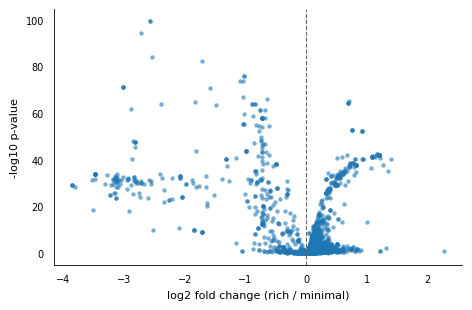

plotted 4067 genes | max -log10(p): 99.6


In [ ]:
# =====================================================================
# CELL 4 — Plain volcano plot (tutorial version)
# ---------------------------------------------------------------------
# Steps:
#   1. Keep genes with both a log2 fold change and a p-value.
#   2. Convert p to -log10(p), so smaller p-values sit higher on the
#      y-axis (p = 0.05 -> 1.3, p = 1e-6 -> 6).
#   3. Scatter x = log2fc (rich / minimal), y = -log10(p), single color.
#   4. Add a dashed line at x = 0 (no change) and label the axes.
#   5. Save via save_fig (PNG + SVG, 600 dpi, into pngs/ and svgs/) and show.
# Uses columns: log2fc, pval. Raw p-values, no multiple-testing
# correction yet (that comes in Cell 5).
# =====================================================================
import matplotlib.pyplot as plt

# 1-2. plotting table
plot_df = v.dropna(subset=['log2fc', 'pval']).copy()
plot_df['neglog10p'] = -np.log10(plot_df['pval'])

# 3-4. scatter
fig, ax = plt.subplots(figsize=FIG_1_5)
ax.scatter(plot_df['log2fc'], plot_df['neglog10p'],
           s=10, linewidths=0, alpha=0.6, color=COMPONENT_COLOR)
ax.axvline(0, lw=0.8, color='0.4', ls='--')
ax.set_xlabel('log2 fold change (rich / minimal)')
ax.set_ylabel('-log10 p-value')
if SHOW_TITLES:
    ax.set_title('Minimal vs rich: per-gene expression change')
plt.tight_layout()

# 5. save and show
save_fig(fig, 'volcano_minimal_vs_rich')
plt.show()

print(f"plotted {len(plot_df)} genes | max -log10(p): {plot_df['neglog10p'].max():.1f}")

transition
unchanged              4003
not subgen → subgen      58
subgen → not subgen       6


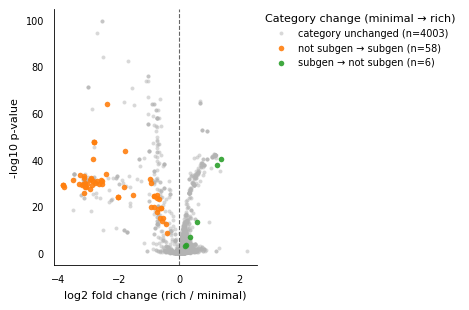

plotted 4067 genes | changed category: 64 | max -log10(p): 99.6


In [ ]:
# =====================================================================
# CELL 4 — Volcano plot, genes that change subgen category colored
# ---------------------------------------------------------------------
# Steps:
#   1. Keep genes with both a log2 fold change and a p-value.
#   2. Convert p to -log10(p), so smaller p-values sit higher on the
#      y-axis (p = 0.05 -> 1.3, p = 1e-6 -> 6).
#   3. Label each gene by its category change minimal -> rich. With
#      possibly_subgen already dropped in Cell 1, the only changes are
#      not_subgen <-> subgen.
#   4. Scatter: grey = category unchanged; colored = changed, one color
#      per transition (drawn on top so they read against the grey mass).
#   5. Dashed line at x = 0, axis labels, legend with per-class counts.
#   6. Save via save_fig (PNG + SVG, 600 dpi, into pngs/ and svgs/) and show.
# Uses columns: log2fc, pval, category_min, category_rich. Raw p-values,
# no multiple-testing correction.
# =====================================================================
import matplotlib.pyplot as plt

# 1-2. plotting table
plot_df = v.dropna(subset=['log2fc', 'pval']).copy()
plot_df['neglog10p'] = -np.log10(plot_df['pval'])

# 3. category change, minimal -> rich
nice = {'subgen': 'subgen', 'not_subgen': 'not subgen'}
changed = plot_df['category_min'] != plot_df['category_rich']
plot_df['transition'] = np.where(
    changed,
    plot_df['category_min'].map(nice) + ' → ' + plot_df['category_rich'].map(nice),
    'unchanged')
print(plot_df['transition'].value_counts().to_string())

# transition -> house-palette color (orange = becomes subgen in rich)
TRANS_COLOR = {
    'not subgen → subgen': SUBGEN_COLOR,       # '#ff7f0e' orange
    'subgen → not subgen': subgen_palette[2],  # '#2ca02c' green
}
# plot changed transitions most-common first, so the legend is ordered
order = plot_df.loc[changed, 'transition'].value_counts().index.tolist()

# 4-5. scatter
fig, ax = plt.subplots(figsize=FIG_1_5)
unch = plot_df[~changed]
ax.scatter(unch['log2fc'], unch['neglog10p'], s=8, linewidths=0, alpha=0.5,
           color='0.7', label=f'category unchanged (n={len(unch)})', zorder=1)
for tr in order:
    sub = plot_df[plot_df['transition'] == tr]
    ax.scatter(sub['log2fc'], sub['neglog10p'], s=16, linewidths=0, alpha=0.9,
               color=TRANS_COLOR.get(tr, 'black'),
               label=f'{tr} (n={len(sub)})', zorder=2)

ax.axvline(0, lw=0.8, color='0.4', ls='--')
ax.set_xlabel('log2 fold change (rich / minimal)')
ax.set_ylabel('-log10 p-value')
if SHOW_TITLES:
    ax.set_title('Minimal vs rich: genes that change subgen category')
ax.legend(title='Category change (minimal → rich)', frameon=False,
          loc='upper left', bbox_to_anchor=(1.02, 1.0), borderaxespad=0)
plt.tight_layout()

# 6. save and show
save_fig(fig, 'volcano_minimal_vs_rich_category_change')
plt.show()

print(f"plotted {len(plot_df)} genes | changed category: {int(changed.sum())} "
      f"| max -log10(p): {plot_df['neglog10p'].max():.1f}")

{'baseline': 1872, 'sig': 480, 'moved': 71, 'flipped': 64}


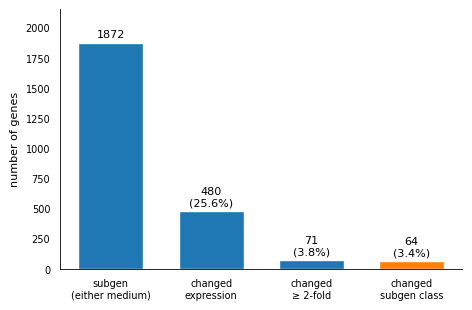

In [ ]:
# =====================================================================
# CELL 7 — Bar chart: few subgen genes actually move between media
# ---------------------------------------------------------------------
# Complements the Cell 5 volcano. Baseline = genes called subgen in
# EITHER medium (so a category change between media is possible). The
# next bars show how few of those genes move reliably, move a lot, or
# flip their subgen call.
# Steps:
#   1. Build the subgen-in-either set from the category columns.
#   2. Count four bars:
#        a. subgen in either medium                       (baseline)
#        b. significant (p < 0.05)
#        c. >= 2-fold shift (|log2fc|>=1) AND p < 0.05
#        d. subgen class changed between media AND p < 0.05
#   3. Draw the bars, annotate each with count (and % of baseline for b-d).
#   4. Save via save_fig (PNG + SVG, 600 dpi, into pngs/ and svgs/), and show.
# Note: a, b, c are nested subsets (each ⊆ the previous). d is NOT nested
#       in b/c: a gene can cross the subgen threshold (=1) with far less
#       than a 2-fold change, so d is shown as a separate endpoint.
#       Significance cutoff (raw p < 0.05) is stated in the caption, not on-axis.
# Uses: v (Cell 1-3: has category_min/rich, log2fc, pval).
# =====================================================================
import matplotlib.pyplot as plt

P_CUT  = 0.05     # significance cutoff (matches the current volcano: raw p)
FC_CUT = 1.0      # |log2fc| >= 1  == 2-fold

# 1. subgen in either medium
sub_min  = v['category_min']  == 'subgen'
sub_rich = v['category_rich'] == 'subgen'
either   = sub_min | sub_rich
e = v[either]

# 2. the four counts
n_base    = len(e)
n_sig     = int((e['pval'] < P_CUT).sum())
n_moved   = int(((e['log2fc'].abs() >= FC_CUT) & (e['pval'] < P_CUT)).sum())
n_flipped = int(((sub_min[either] != sub_rich[either]) & (e['pval'] < P_CUT)).sum())

labels = ['subgen\n(either medium)',
          'changed\nexpression',
          'changed\n≥ 2-fold',
          'changed\nsubgen class']
counts = [n_base, n_sig, n_moved, n_flipped]
print(dict(zip(['baseline','sig','moved','flipped'], counts)))

# 3. plot
# Nested funnel (baseline -> sig -> moved -> flipped). House palette:
# blue for the baseline/intermediate bars, orange for the subgen-class endpoint.
bar_colors = [COMPONENT_COLOR, COMPONENT_COLOR, COMPONENT_COLOR, SUBGEN_COLOR]
fig, ax = plt.subplots(figsize=FIG_1_5)
bars = ax.bar(labels, counts, color=bar_colors, width=0.65)
ax.set_ylabel('number of genes')
if SHOW_TITLES:
    ax.set_title('Subgen genes rarely change expression enough to change class')
ax.set_ylim(0, n_base * 1.15)
for i, (b, c) in enumerate(zip(bars, counts)):
    # baseline bar: count only (a "% of itself" label is meaningless)
    label = f'{c}' if i == 0 else f'{c}\n({100*c/n_base:.1f}%)'
    ax.text(b.get_x() + b.get_width()/2, c + n_base*0.015,
            label, ha='center', va='bottom')
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
fig.tight_layout()

# 4. save and show
save_fig(fig, 'subgen_movement_bars')
plt.show()

In [ ]:
# =====================================================================
# CELL 8 — Annotated table: genes that drop INTO subgen in rich (>=2-fold)
# ---------------------------------------------------------------------
# The orange points on the volcano: not_subgen in minimal -> subgen in
# rich, with |log2fc| >= 1 (>= 2-fold lower in rich). Adds EcoCyc gene
# name, product and functional annotation, and writes a TSV + CSV.
# Self-contained: loads the EcoCyc gene table here. Uses: v (Cell 1-3),
# mn (Cell 1) for protein_id, which v does not carry.
# =====================================================================
import os
import pandas as pd

FIG_DIR = str(OUT_DIR)   # (already set in the style cell; repeated so this runs alone)
os.makedirs(FIG_DIR, exist_ok=True)

# EcoCyc gene table (gene_id == Object ID)
ecoli_genes_path = f"{DATA}/All-genes-of-E.-coli-K-12-substr.-MG1655.txt"
ecoli_genes_pd   = pd.read_csv(ecoli_genes_path, sep='\t')

FC_CUT = 1.0   # |log2fc| >= 1 == 2-fold

# 1. the gene set (orange, >=2-fold)
mask = ((v['category_min'] == 'not_subgen') &
        (v['category_rich'] == 'subgen') &
        (v['log2fc'].abs() >= FC_CUT) &
        (v['pval'].notna()))
tbl = v[mask].copy()

# 1b. add protein_id (v does not carry it; bring it from the minimal file by gene_id)
tbl['protein_id'] = tbl['gene_id'].map(dict(zip(mn['gene_id'], mn['protein_id'])))

# 2. annotate from EcoCyc (gene_id == Object ID)
ann = ecoli_genes_pd[['Object ID', 'Gene Name', 'Product',
                      'Characterization', 'GO terms (biological process)']]
tbl = tbl.merge(ann, left_on='gene_id', right_on='Object ID', how='left')

# 3. tidy: shorten the GO string to the first few terms, order columns, sort
tbl['GO (first 3)'] = (tbl['GO terms (biological process)'].fillna('')
                       .apply(lambda s: ' // '.join(s.split(' // ')[:3])))
tbl = tbl.rename(columns={'Gene Name': 'gene', 'Product': 'product',
                          'Characterization': 'evidence'})
out = (tbl[['gene', 'gene_id', 'protein_id', 'product', 'evidence',
            'GO (first 3)', 'mean_min', 'mean_rich', 'log2fc', 'pval']]
       .sort_values('log2fc')                      # most strongly down in rich first
       .round({'mean_min': 2, 'mean_rich': 2, 'log2fc': 2, 'pval': 4})
       .reset_index(drop=True))

# 4. save (into figures/, same convention as save_fig) and show
out.to_csv(f'{FIG_DIR}/table_dropped_into_subgen_rich.tsv', sep='\t', index=False)
out.to_csv(f'{FIG_DIR}/table_dropped_into_subgen_rich.csv', index=False)
print(f"{len(out)} genes -> figures/table_dropped_into_subgen_rich.(tsv|csv)")

with pd.option_context('display.max_rows', None, 'display.width', 200,
                       'display.max_colwidth', 60):
    print(out.to_string(index=False))
out   # renders as a table in the notebook

40 genes -> figures/table_dropped_into_subgen_rich.(tsv|csv)
gene gene_id             protein_id                                                                  product           evidence                                                                                                                                                                                 GO (first 3)  mean_min  mean_rich  log2fc  pval
hdeA EG11398        EG11398-MONOMER                                   periplasmic acid stress chaperone HdeA WELL-CHARACTERIZED                                                                                                   protein folding // cellular response to acidic pH // cellular stress response to acidic pH      2.99       0.21   -3.85   0.0
hdeB EG11399        EG11399-MONOMER                                   periplasmic acid stress chaperone HdeB WELL-CHARACTERIZED                                                                                                            

,gene,gene_id,protein_id,product,evidence,GO (first 3),mean_min,mean_rich,log2fc,pval
0,hdeA,EG11398,EG11398-MONOMER,periplasmic acid stress chaperone HdeA,WELL-CHARACTERIZED,protein folding // cellular response to acidic...,2.99,0.21,-3.85,0.0
1,hdeB,EG11399,EG11399-MONOMER,periplasmic acid stress chaperone HdeB,WELL-CHARACTERIZED,cellular stress response to acidic pH // respo...,2.99,0.21,-3.85,0.0
2,yhiD,EG11400,EG11400-MONOMER,inner membrane protein YhiD,UNCHARACTERIZED,,2.99,0.21,-3.85,0.0
3,yhhA,EG11184,EG11184-MONOMER,DUF2756 domain-containing protein YhhA,PARTIAL,positive regulation of gene expression // resp...,1.36,0.10,-3.81,0.0
4,iraP,EG11256,EG11256-MONOMER,anti-adaptor protein IraP,WELL-CHARACTERIZED,cellular response to starvation // positive re...,3.47,0.30,-3.53,0.0
5,rhtB,EG11469,RHTB-MONOMER,L-homoserine/L-homoserine lactone/L-threonine ...,WELL-CHARACTERIZED,amino acid transport // threonine transport //...,1.46,0.15,-3.31,0.0
6,ydcL,G6742,G6742-MONOMER,DUF3313 domain-containing lipoprotein YdcL,UNCHARACTERIZED,,5.09,0.53,-3.28,0.0
7,fxsA,G7832,G7832-MONOMER,protein FxsA,UNCHARACTERIZED,,3.59,0.39,-3.22,0.0
8,bipP,EG12254,EG12254-MONOMER,proteolysis regulator BipP,PARTIAL,proteolysis // regulation of proteolysis // re...,3.86,0.43,-3.18,0.0
9,soxS,EG10958,PD00406,DNA-binding transcriptional dual regulator SoxS,WELL-CHARACTERIZED,regulation of DNA-templated transcription,4.03,0.45,-3.16,0.0


In [ ]:
# =====================================================================
# CELL 9 — Annotated table: genes that leave subgen in rich
#          (subgen in minimal -> not_subgen in rich; the green points)
# ---------------------------------------------------------------------
# Self-contained: reads the two seed-CI files and the EcoCyc gene table
# directly, so it does not depend on the volcano cells. possibly_subgen
# genes are dropped first (either medium), matching the volcano.
# A near_cutoff flag marks genes whose means both sit ~0.7-1.3, i.e. the
# flip is just crossing the mean=1 boundary rather than a real shift.
# =====================================================================
import os
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind_from_stats

FIG_DIR = str(OUT_DIR)
os.makedirs(FIG_DIR, exist_ok=True)

# --- paths ---
min_path  = f"{DATA_MIN}/subgen_seed_ci_pergene_successful.tsv"
rich_path = f"{DATA_RICH}/subgen_seed_ci_pergene_successful.tsv"
genes_path = f"{DATA}/All-genes-of-E.-coli-K-12-substr.-MG1655.txt"

# --- load + merge (same as volcano Cell 1) ---
cols = ['gene_id', 'cistron_id', 'protein_id', 'n_seeds', 'mean', 'std', 'category']
mn = pd.read_csv(min_path,  sep='\t')
rc = pd.read_csv(rich_path, sep='\t')
v = mn[cols].merge(rc[cols], on=['gene_id', 'cistron_id', 'protein_id'],
                   suffixes=('_min', '_rich'))

# drop possibly_subgen (either medium)
_poss = (v['category_min'] == 'possibly_subgen') | (v['category_rich'] == 'possibly_subgen')
v = v[~_poss].copy()

# --- log2 fold change (rich / minimal) and Welch p from summary stats ---
both_pos = (v['mean_min'] > 0) & (v['mean_rich'] > 0)
v['log2fc'] = np.where(both_pos,
                       np.log2(v['mean_rich'].where(both_pos) / v['mean_min'].where(both_pos)),
                       np.nan)
with np.errstate(divide='ignore', invalid='ignore'):
    _, v['pval'] = ttest_ind_from_stats(
        v['mean_rich'], v['std_rich'], v['n_seeds_rich'],
        v['mean_min'],  v['std_min'],  v['n_seeds_min'], equal_var=False)

# --- select: subgen (minimal) -> not_subgen (rich) ---
g = v[(v['category_min'] == 'subgen') & (v['category_rich'] == 'not_subgen')].copy()

# --- annotate from EcoCyc (gene_id == Object ID) ---
genes = pd.read_csv(genes_path, sep='\t')
g = g.merge(genes[['Object ID', 'Gene Name', 'Product',
                   'Characterization', 'GO terms (biological process)']],
            left_on='gene_id', right_on='Object ID', how='left')

# flag threshold-straddlers (both means within ~0.3 of the mean=1 cutoff)
g['near_cutoff'] = g['mean_min'].between(0.7, 1.3) & g['mean_rich'].between(0.7, 1.3)

# tidy GO to first 3 terms, rename, order, sort by largest increase first
g['GO (first 3)'] = (g['GO terms (biological process)'].fillna('')
                     .apply(lambda s: ' // '.join(s.split(' // ')[:3])))
g = g.rename(columns={'Gene Name': 'gene', 'Product': 'product',
                      'Characterization': 'evidence'})
out = (g[['gene', 'gene_id', 'protein_id', 'product', 'evidence',
          'GO (first 3)', 'mean_min', 'mean_rich', 'log2fc', 'pval', 'near_cutoff']]
       .sort_values('log2fc', ascending=False)      # biggest increase in rich first
       .round({'mean_min': 2, 'mean_rich': 2, 'log2fc': 2, 'pval': 4})
       .reset_index(drop=True))

# --- save + show ---
out.to_csv(f'{FIG_DIR}/table_left_subgen_in_rich.tsv', sep='\t', index=False)
out.to_csv(f'{FIG_DIR}/table_left_subgen_in_rich.csv', index=False)
print(f"{len(out)} genes (subgen -> not_subgen) | "
      f"robust (|log2fc|>=1): {(out['log2fc'].abs() >= 1).sum()} | "
      f"near cutoff: {out['near_cutoff'].sum()}")
print(f"saved -> {FIG_DIR}/table_left_subgen_in_rich.(tsv|csv)")

with pd.option_context('display.max_rows', None, 'display.width', 200,
                       'display.max_colwidth', 60):
    print(out.to_string(index=False))
out   # renders as a table in the notebook

6 genes (subgen -> not_subgen) | robust (|log2fc|>=1): 2 | near cutoff: 4
saved -> figures/table_left_subgen_in_rich.(tsv|csv)
gene gene_id      protein_id                                  product           evidence                                                                               GO (first 3)  mean_min  mean_rich  log2fc   pval  near_cutoff
recN EG10831 EG10831-MONOMER                  DNA repair protein RecN            PARTIAL                                       DNA recombination // DNA repair // response to X-ray      0.90       2.38    1.40 0.0000        False
gluQ EG11362 EG11362-MONOMER glutamyl-Q tRNA<sup>Asp</sup> synthetase WELL-CHARACTERIZED                   tRNA aminoacylation // glutamyl-tRNA aminoacylation // tRNA modification      0.75       1.80    1.27 0.0000        False
yraQ   G7645   G7645-MONOMER             permease family protein YraQ    UNCHARACTERIZED                                                                                                 0

,gene,gene_id,protein_id,product,evidence,GO (first 3),mean_min,mean_rich,log2fc,pval,near_cutoff
0,recN,EG10831,EG10831-MONOMER,DNA repair protein RecN,PARTIAL,DNA recombination // DNA repair // response to...,0.90,2.38,1.40,0.0000,False
1,gluQ,EG11362,EG11362-MONOMER,glutamyl-Q tRNA<sup>Asp</sup> synthetase,WELL-CHARACTERIZED,tRNA aminoacylation // glutamyl-tRNA aminoacyl...,0.75,1.80,1.27,0.0000,False
2,yraQ,G7645,G7645-MONOMER,permease family protein YraQ,UNCHARACTERIZED,,0.83,1.25,0.59,0.0000,True
3,fucU,EG10355,EG10355-MONOMER,L-fucose mutarotase,WELL-CHARACTERIZED,monosaccharide metabolic process // L-fucose m...,0.84,1.08,0.36,0.0000,True
4,yiiX,EG11882,EG11882-MONOMER,putative lipid-binding hydrolase YiiX,PARTIAL,positive regulation of gene expression // resp...,0.93,1.08,0.22,0.0004,True
5,smf,EG11604,EG11604-MONOMER,protein Smf,UNCHARACTERIZED,DNA-mediated transformation,0.94,1.08,0.20,0.0011,True


In [ ]:
import pandas as pd

# per-medium seed-CI files
min_path  = f"{DATA_MIN}/subgen_seed_ci_pergene_successful.tsv"
rich_path = f"{DATA_RICH}/subgen_seed_ci_pergene_successful.tsv"

mn = pd.read_csv(min_path,  sep='\t')
rc = pd.read_csv(rich_path, sep='\t')

# category counts side by side
counts = pd.DataFrame({
    'minimal': mn['category'].value_counts(),
    'rich':    rc['category'].value_counts(),
}).fillna(0).astype(int)

# order rows sensibly and add a total
order = ['subgen', 'possibly_subgen', 'not_subgen', 'never_expressed']
counts = counts.reindex([c for c in order if c in counts.index])
counts.loc['total'] = counts.sum()

print(counts.to_string())

                 minimal  rich
category                      
subgen              1848  1872
possibly_subgen       62    60
not_subgen          2264  2242
never_expressed      137   137
total               4311  4311
